# Label check

Visual check that the YOLO labels written by `make_yolo_split.py` sit on the starfish.
Boxes are drawn from the **label files** (converted back to pixels), so this tests the whole pipeline,
including the assumption that `train.csv` boxes are top-left based.

Needs `pillow` and `matplotlib` in the venv.

In [1]:
import ast, csv, random
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

DATA = Path.cwd().parent / "data" if Path.cwd().name == "data_scripts" else Path.cwd() / "data"
YOLO = DATA / "yolo"
SPLIT = "v0val_pos"
W, H = 1280, 720

rows = list(csv.DictReader(open(YOLO / "splits" / SPLIT / "split.csv")))
raw = {r["image_id"]: ast.literal_eval(r["annotations"]) for r in csv.DictReader(open(DATA / "train.csv"))}
print(len(rows), "frames in split", SPLIT)

9484 frames in split v0val_pos


In [2]:
def paths(image_id):
    v, f = image_id.split("-")
    return YOLO / "images" / f"video_{v}" / f"{f}.jpg", YOLO / "labels" / f"video_{v}" / f"{f}.txt"

def yolo_boxes(image_id):
    """Label file -> list of (x1, y1, x2, y2) in pixels."""
    out = []
    for line in paths(image_id)[1].read_text().splitlines():
        _, cx, cy, w, h = map(float, line.split())
        out.append(((cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H))
    return out

def show(image_id, ax=None):
    img = Image.open(paths(image_id)[0]).convert("RGB")
    d = ImageDraw.Draw(img)
    for b in yolo_boxes(image_id):
        d.rectangle(b, outline=(0, 255, 0), width=2)
    ax = ax or plt.subplots(figsize=(14, 8))[1]
    ax.imshow(img); ax.set_title(f"{image_id}  ({len(yolo_boxes(image_id))} boxes)"); ax.axis("off")

## Random frames with boxes, from train and val

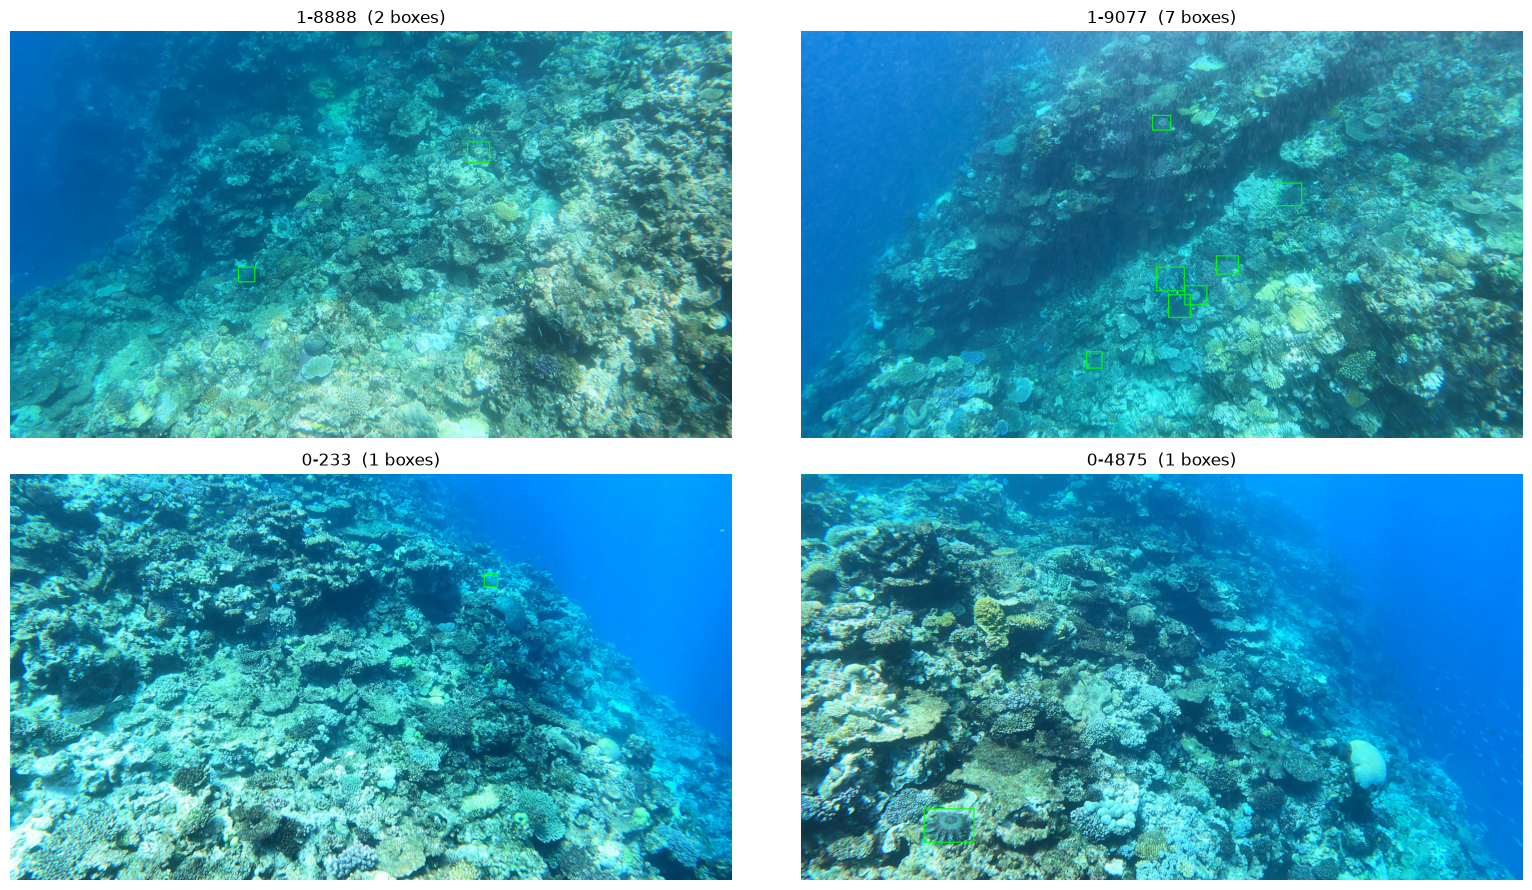

In [3]:
random.seed(0)
pos = {s: [r["image_id"] for r in rows if r["split"] == s and int(r["n_boxes"]) > 0] for s in ("train", "val")}
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, iid in zip(axes.flat, random.sample(pos["train"], 2) + random.sample(pos["val"], 2)):
    show(iid, ax)
plt.tight_layout()

## Densest frame, and a frame with a box clipped at the image edge

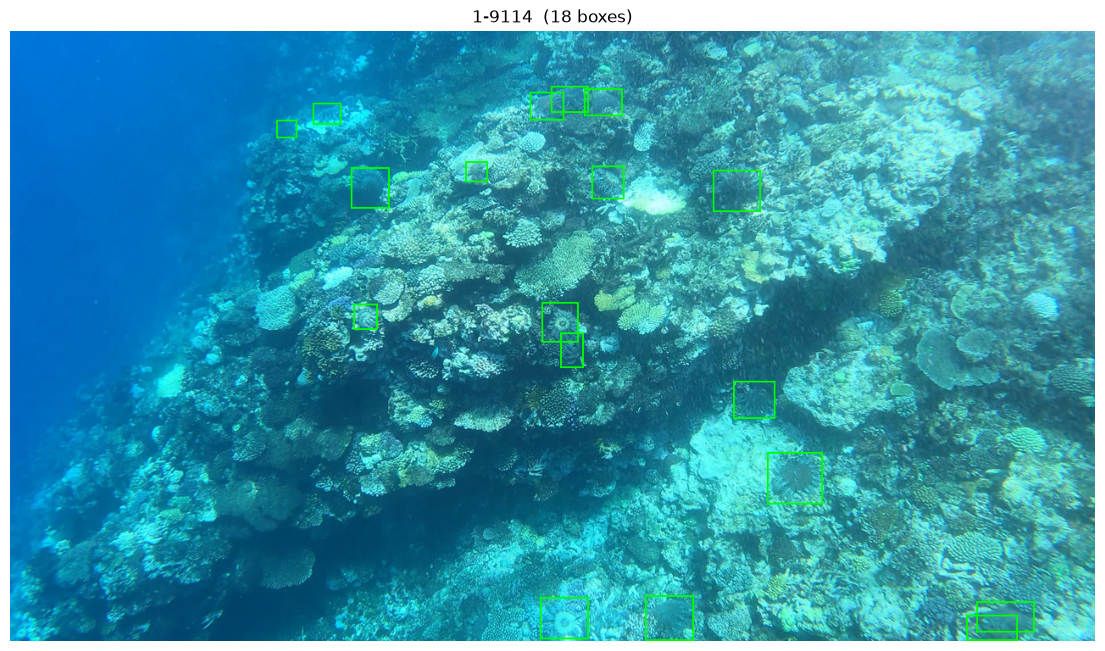

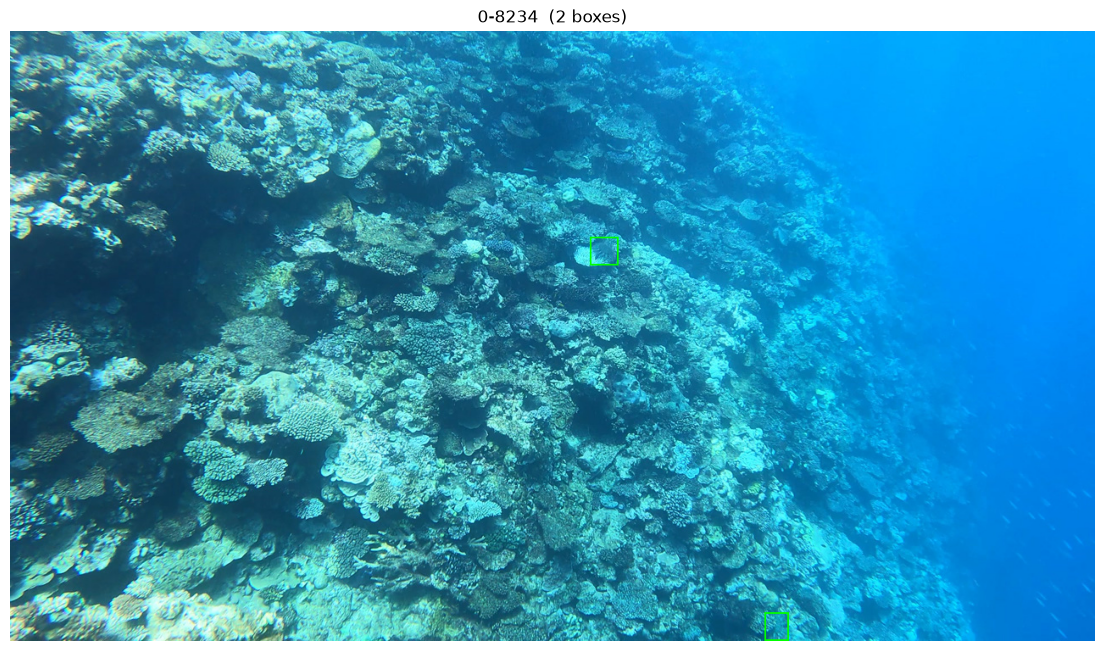

In [4]:
densest = max(rows, key=lambda r: int(r["n_boxes"]))["image_id"]
edge = next(i for i, bs in raw.items() if any(b["x"] + b["width"] > W or b["y"] + b["height"] > H for b in bs))
show(densest); show(edge)

## Zoomed crops around random boxes

The quickest way to judge whether boxes are tight and centered: each crop is the box plus 50% padding on each side.

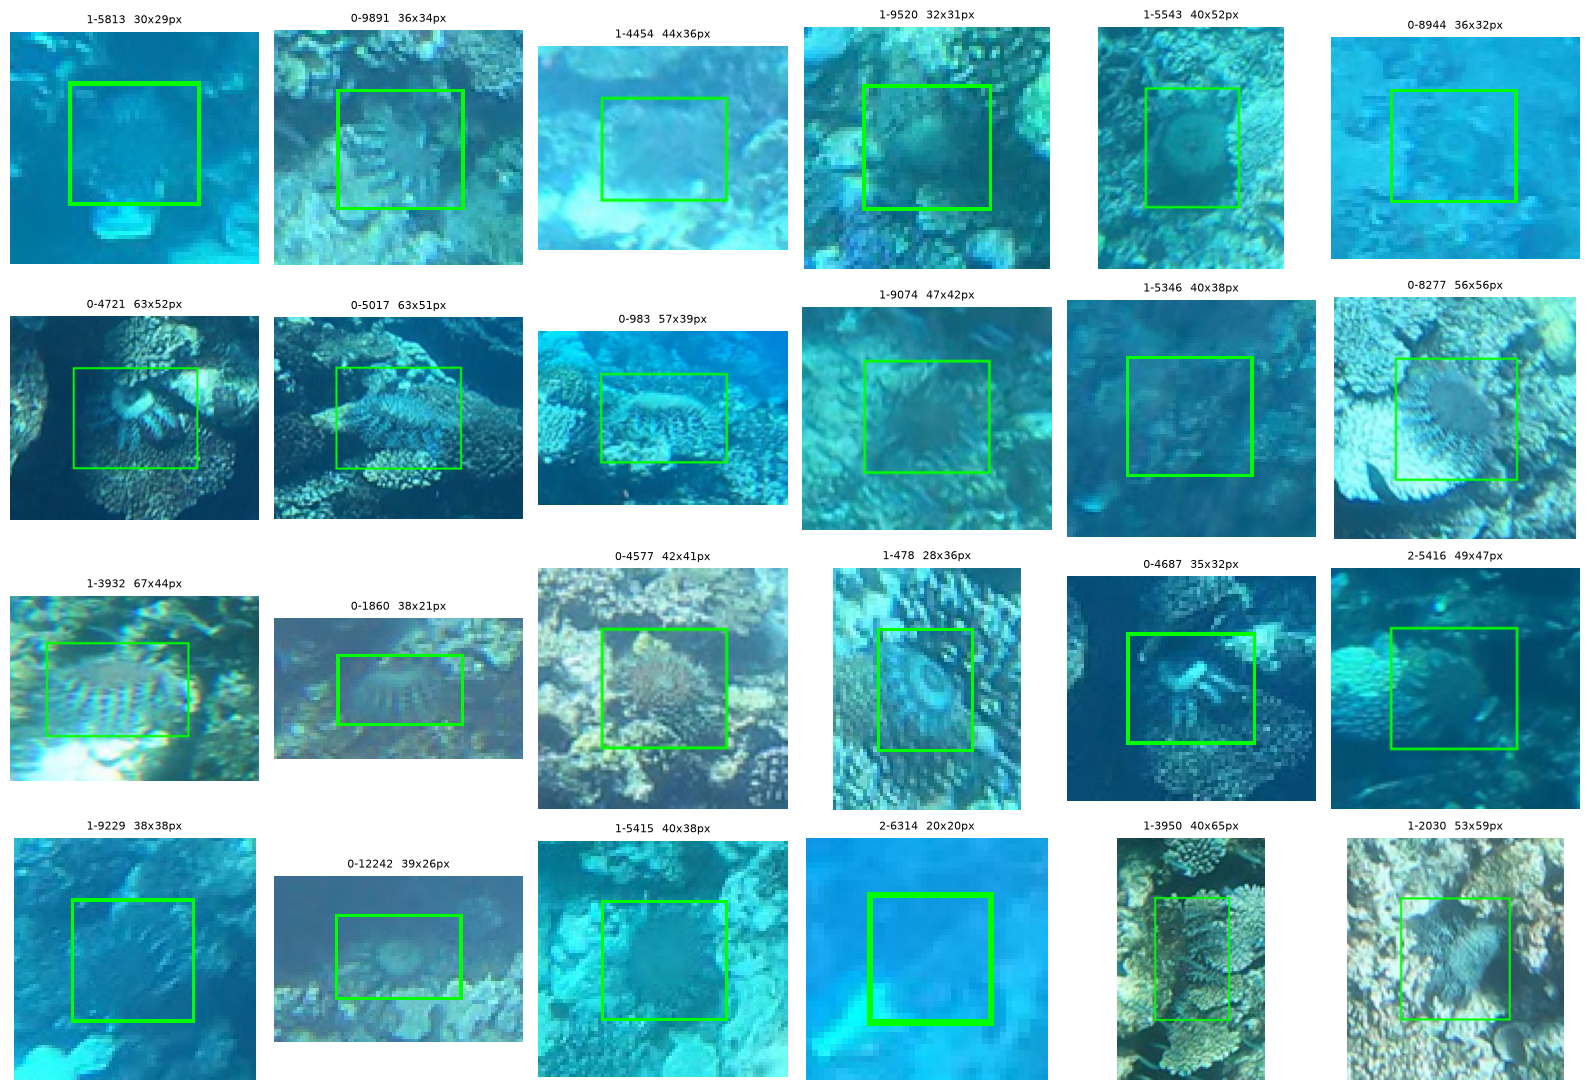

In [5]:
random.seed(1)
picks = [(iid, b) for iid in random.sample(pos["train"] + pos["val"], 24) for b in [random.choice(yolo_boxes(iid))]]
fig, axes = plt.subplots(4, 6, figsize=(16, 11))
for ax, (iid, (x1, y1, x2, y2)) in zip(axes.flat, picks):
    pw, ph = (x2 - x1) / 2, (y2 - y1) / 2
    img = Image.open(paths(iid)[0]).convert("RGB")
    ImageDraw.Draw(img).rectangle((x1, y1, x2, y2), outline=(0, 255, 0), width=1)
    ax.imshow(img.crop((max(0, x1 - pw), max(0, y1 - ph), min(W, x2 + pw), min(H, y2 + ph))))
    ax.set_title(f"{iid}  {x2 - x1:.0f}x{y2 - y1:.0f}px", fontsize=8); ax.axis("off")
plt.tight_layout()